In [ ]:
!pip install pandas numpy scikit-learn matplotlib seaborn
!pip install tensorflow keras


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving DSL-StrongPasswordData.csv to DSL-StrongPasswordData.csv


In [ ]:
import pandas as pd

# Load the CSV file into a Pandas DataFrame (adjust file path if needed)
data = pd.read_csv('DSL-StrongPasswordData.csv')

# Preview the data
print(data.head())

# Check the columns and structure
print(data.info())


  subject  sessionIndex  rep  H.period  DD.period.t  UD.period.t     H.t  \
0    s002             1    1    0.1491       0.3979       0.2488  0.1069   
1    s002             1    2    0.1111       0.3451       0.2340  0.0694   
2    s002             1    3    0.1328       0.2072       0.0744  0.0731   
3    s002             1    4    0.1291       0.2515       0.1224  0.1059   
4    s002             1    5    0.1249       0.2317       0.1068  0.0895   

   DD.t.i  UD.t.i     H.i  ...     H.a  DD.a.n  UD.a.n     H.n  DD.n.l  \
0  0.1674  0.0605  0.1169  ...  0.1349  0.1484  0.0135  0.0932  0.3515   
1  0.1283  0.0589  0.0908  ...  0.1412  0.2558  0.1146  0.1146  0.2642   
2  0.1291  0.0560  0.0821  ...  0.1621  0.2332  0.0711  0.1172  0.2705   
3  0.2495  0.1436  0.1040  ...  0.1457  0.1629  0.0172  0.0866  0.2341   
4  0.1676  0.0781  0.0903  ...  0.1312  0.1582  0.0270  0.0884  0.2517   

   UD.n.l     H.l  DD.l.Return  UD.l.Return  H.Return  
0  0.2583  0.1338       0.3509       0.217

In [ ]:
# Check for missing values
print(data.isnull().sum())

# Drop or fill missing values if necessary
data = data.dropna()


subject            0
sessionIndex       0
rep                0
H.period           0
DD.period.t        0
UD.period.t        0
H.t                0
DD.t.i             0
UD.t.i             0
H.i                0
DD.i.e             0
UD.i.e             0
H.e                0
DD.e.five          0
UD.e.five          0
H.five             0
DD.five.Shift.r    0
UD.five.Shift.r    0
H.Shift.r          0
DD.Shift.r.o       0
UD.Shift.r.o       0
H.o                0
DD.o.a             0
UD.o.a             0
H.a                0
DD.a.n             0
UD.a.n             0
H.n                0
DD.n.l             0
UD.n.l             0
H.l                0
DD.l.Return        0
UD.l.Return        0
H.Return           0
dtype: int64


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encode the 'subject' column (target) into numbers
le = LabelEncoder()
data['subject'] = le.fit_transform(data['subject'])  # Encode subject IDs


In [ ]:
from sklearn.preprocessing import StandardScaler

# Select the feature columns (exclude 'subject', 'sessionIndex', 'rep')
X = data.drop(['subject', 'sessionIndex', 'rep'], axis=1)

# Standardize the feature columns
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# The target variable (user ID)
y = data['subject']


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Predict on the test data
y_pred = knn.predict(X_test)

# Evaluate the model
print("KNN Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


KNN Accuracy: 0.8356209150326798
              precision    recall  f1-score   support

           0       0.55      0.87      0.67       116
           1       0.79      0.79      0.79       107
           2       0.75      0.90      0.82       113
           3       0.83      0.92      0.87       121
           4       0.63      0.80      0.71        99
           5       0.76      0.76      0.76       124
           6       0.84      0.95      0.89       135
           7       0.88      0.78      0.83       116
           8       0.92      0.84      0.88       129
           9       0.75      0.94      0.83       114
          10       0.81      0.72      0.76       122
          11       0.66      0.94      0.78       112
          12       0.91      0.94      0.93       118
          13       0.92      0.71      0.80       115
          14       0.82      0.95      0.88       122
          15       0.88      0.74      0.81       124
          16       0.74      0.83      0.78     

In [ ]:
from sklearn.svm import SVC

# Initialize and train the SVM model
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

# Predict on the test data
y_pred = svm.predict(X_test)

# Evaluate the model
print("SVM Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


SVM Accuracy: 0.8504901960784313
              precision    recall  f1-score   support

           0       0.69      0.78      0.73       116
           1       0.78      0.81      0.79       107
           2       0.79      0.90      0.84       113
           3       0.89      0.88      0.89       121
           4       0.63      0.81      0.71        99
           5       0.77      0.72      0.74       124
           6       0.90      0.91      0.91       135
           7       0.83      0.84      0.83       116
           8       0.88      0.84      0.86       129
           9       0.83      0.87      0.85       114
          10       0.76      0.80      0.78       122
          11       0.78      0.95      0.85       112
          12       0.94      0.95      0.95       118
          13       0.80      0.75      0.77       115
          14       0.92      0.93      0.93       122
          15       0.77      0.76      0.76       124
          16       0.76      0.73      0.74     

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
rf = RandomForestClassifier(n_estimators=100)
rf.fit(X_train, y_train)

# Predict on the test data
y_pred = rf.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Random Forest Accuracy: 0.9305555555555556
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       116
           1       0.91      0.89      0.90       107
           2       0.88      0.95      0.91       113
           3       0.95      0.95      0.95       121
           4       0.85      0.87      0.86        99
           5       0.92      0.81      0.86       124
           6       0.96      0.93      0.94       135
           7       0.97      0.89      0.93       116
           8       0.94      0.93      0.94       129
           9       0.96      0.96      0.96       114
          10       0.97      0.93      0.95       122
          11       0.90      0.98      0.94       112
          12       0.97      0.97      0.97       118
          13       0.97      0.85      0.91       115
          14       0.98      0.98      0.98       122
          15       0.98      0.79      0.88       124
          16       0.87      0.96     

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Build a simple neural network
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')  # Multi-class classification output
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print("Neural Network Accuracy:", accuracy)


Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


357/357 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1902 - loss: 3.3175 - val_accuracy: 0.6173 - val_loss: 1.5804
Epoch 2/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6524 - loss: 1.3670 - val_accuracy: 0.7395 - val_loss: 1.0133
Epoch 3/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7553 - loss: 0.9322 - val_accuracy: 0.7812 - val_loss: 0.8304
Epoch 4/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7950 - loss: 0.7457 - val_accuracy: 0.8050 - val_loss: 0.7409
Epoch 5/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8238 - loss: 0.6341 - val_accuracy: 0.8267 - val_loss: 0.6870
Epoch 6/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8344 - loss: 0.5955 - val_accuracy: 0.8340 - val_loss: 0.6448
Epoch 7/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8441 - loss: 0.5417 - val_accuracy: 0.8417 - val_loss: 0.6167
Epoch 8/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8656 - loss: 0.4892 - val_accuracy: 0.8512 - val_

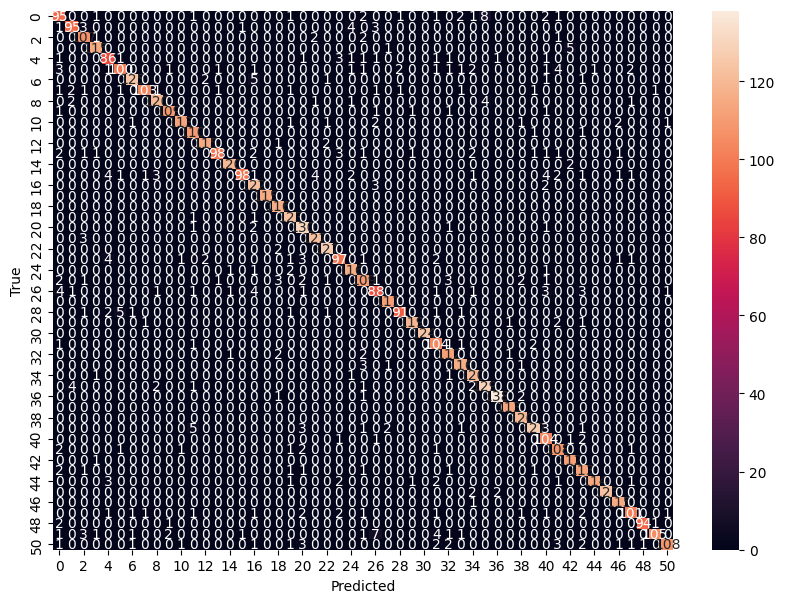

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [ ]:
# Save the Random Forest model
import joblib
joblib.dump(rf, 'rf_keystroke_model.pkl')

# Save the neural network model
model.save('keystroke_nn_model.h5')


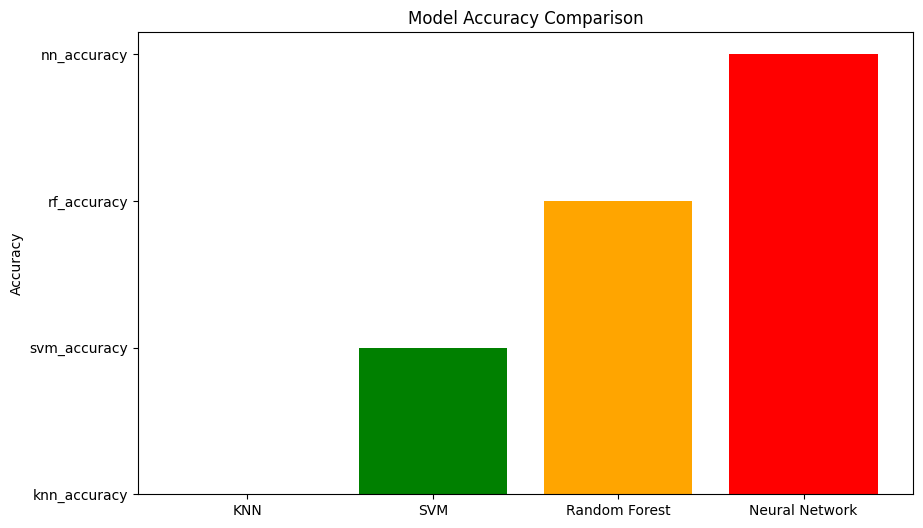

In [ ]:
import matplotlib.pyplot as plt

# Assuming you have stored the accuracy of different models
model_names = ['KNN', 'SVM', 'Random Forest', 'Neural Network']
accuracies = ['knn_accuracy', 'svm_accuracy', 'rf_accuracy', 'nn_accuracy']

plt.figure(figsize=(10,6))
plt.bar(model_names, accuracies, color=['blue', 'green', 'orange', 'red'])
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()


In [ ]:
!pip install joblib


In [ ]:
import joblib

# Save KNN model
joblib.dump(knn, 'knn_model.pkl')

# Save SVM model
joblib.dump(svm, 'svm_model.pkl')

# Save Random Forest model
joblib.dump(rf, 'rf_model.pkl')


['rf_model.pkl']

In [ ]:
# Load saved KNN model
knn_loaded = joblib.load('knn_model.pkl')

# Load saved SVM model
svm_loaded = joblib.load('svm_model.pkl')

# Load saved Random Forest model
rf_loaded = joblib.load('rf_model.pkl')


In [ ]:
# Save the neural network model in .h5 format
model.save('neural_network_model.h5')


In [ ]:
from tensorflow.keras.models import load_model

# Load the neural network model
nn_model_loaded = load_model('neural_network_model.h5')


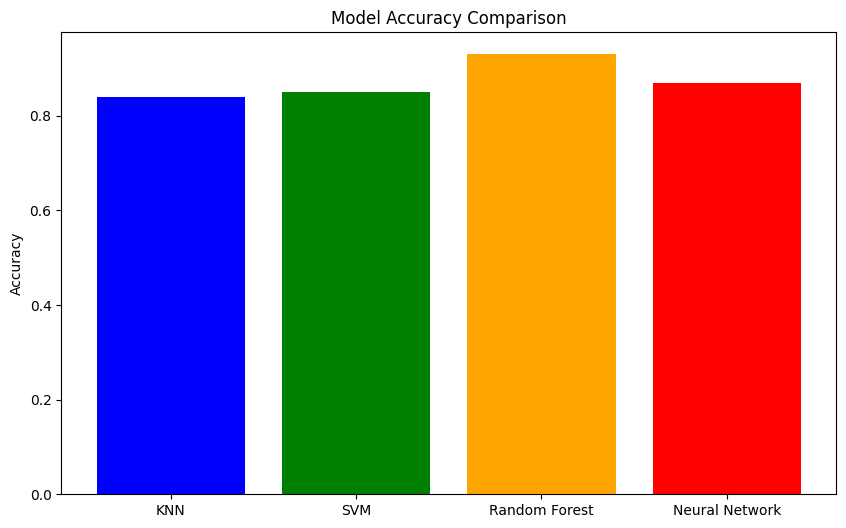

In [ ]:
import matplotlib.pyplot as plt
knn_accuracy = 0.84
svm_accuracy = 0.85
rf_accuracy = 0.93
nn_accuracy = 0.87
# Assuming you have stored the accuracy of different models
model_names = ['KNN', 'SVM', 'Random Forest', 'Neural Network']
accuracies = [knn_accuracy, svm_accuracy, rf_accuracy, nn_accuracy]

plt.figure(figsize=(10,6))
plt.bar(model_names, accuracies, color=['blue', 'green', 'orange', 'red'])
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()


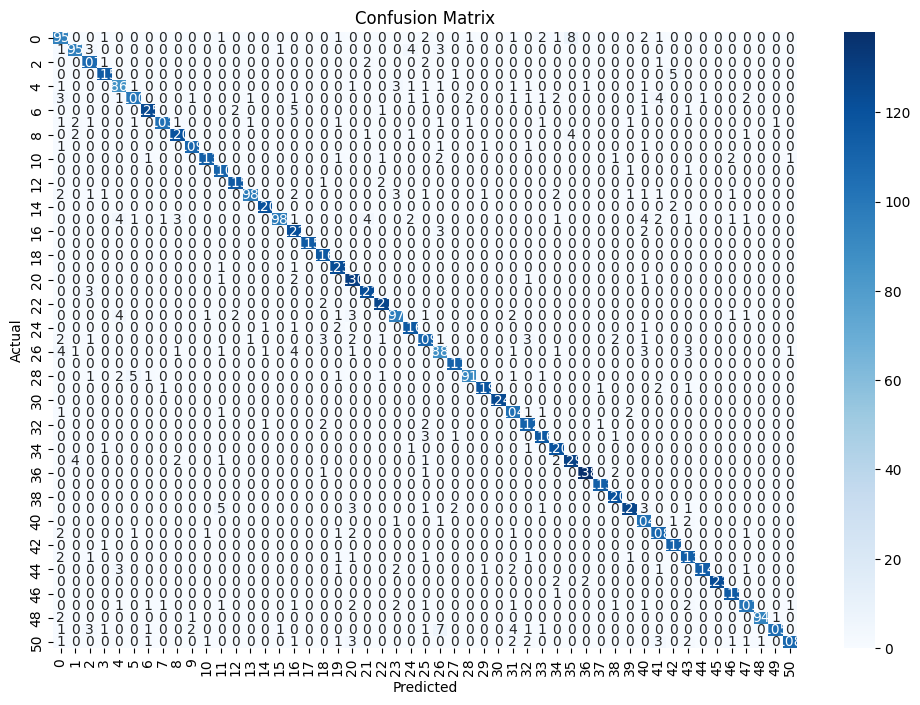

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Assuming y_pred is the predicted labels and y_test is the actual labels for a chosen model (e.g., Random Forest)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12,8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


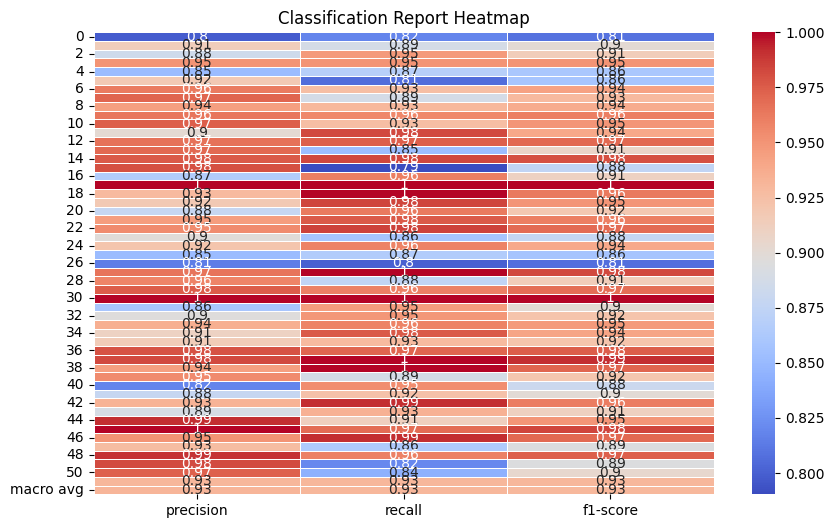

In [ ]:
from sklearn.metrics import classification_report

# Print the classification report for a model
report = classification_report(y_test, y_pred, output_dict=True)

# Convert the classification report into a DataFrame for visualization
report_df = pd.DataFrame(report).transpose()

# Visualize as a heatmap
plt.figure(figsize=(10,6))
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Classification Report Heatmap')
plt.show()


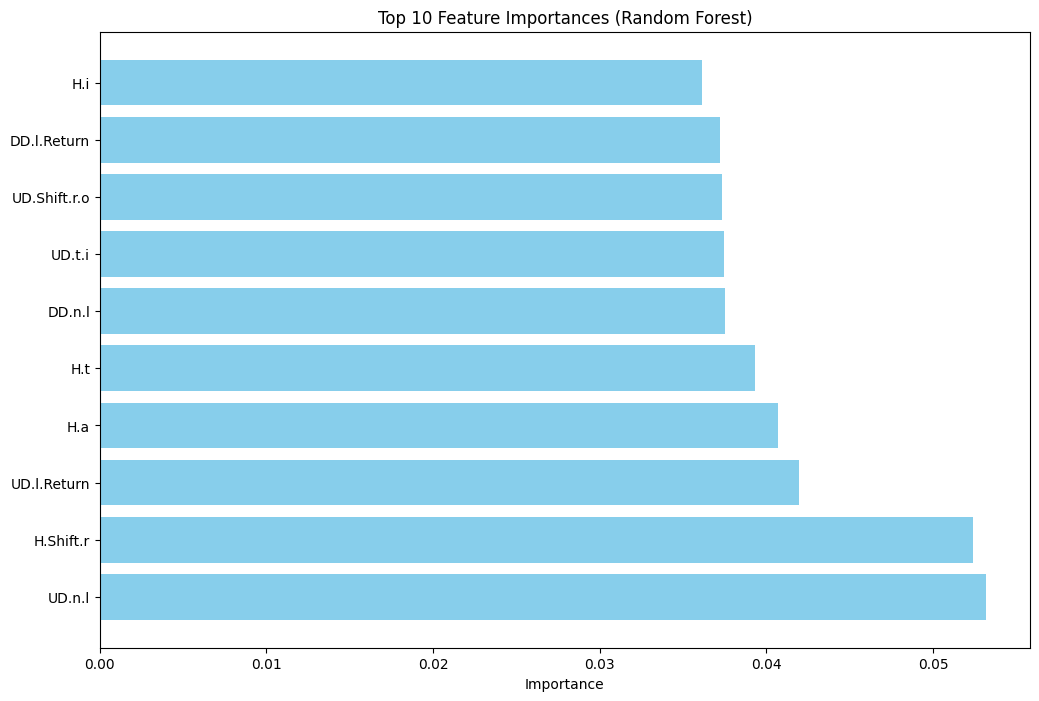

In [ ]:
import numpy as np

# Get feature importances from the trained random forest model
feature_importances = rf.feature_importances_

# Get feature names
feature_names = X.columns

# Sort feature importances in descending order
sorted_idx = np.argsort(feature_importances)[::-1]

# Plot the top features
plt.figure(figsize=(12,8))
plt.barh(feature_names[sorted_idx][:10], feature_importances[sorted_idx][:10], color='skyblue')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.show()


In [ ]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Encode the target variable
le = LabelEncoder()
y_encoded = le.fit_transform(data['subject'])

# One-hot encode the target variable
y_onehot = np.eye(len(le.classes_))[y_encoded]

# Standardize and reshape features
X = data.drop(['subject', 'sessionIndex', 'rep'], axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape X to 3D for RNN/LSTM input
X_scaled_reshaped = X_scaled.reshape((X_scaled.shape[0], X_scaled.shape[1], 1))

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_scaled_reshaped, y_onehot, test_size=0.3, random_state=42)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN

# Build the RNN model
rnn_model = Sequential([
    SimpleRNN(64, activation='relu', input_shape=(X_train.shape[1], 1), return_sequences=True),
    SimpleRNN(32, activation='relu'),
    Dense(y_train.shape[1], activation='softmax')  # Match output layer to one-hot encoded classes
])

# Compile and train the model
rnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
rnn_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

# Evaluate the model
rnn_loss, rnn_accuracy = rnn_model.evaluate(X_test, y_test)
print("RNN Accuracy:", rnn_accuracy)


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.1454 - loss: 3.4202 - val_accuracy: 0.4597 - val_loss: 1.9689
Epoch 2/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.5161 - loss: 1.7629 - val_accuracy: 0.6173 - val_loss: 1.3710
Epoch 3/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6367 - loss: 1.2939 - val_accuracy: 0.6898 - val_loss: 1.0928
Epoch 4/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7007 - loss: 1.0275 - val_accuracy: 0.7027 - val_loss: 1.0535
Epoch 5/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7397 - loss: 0.9013 - val_accuracy: 0.7556 - val_loss: 0.8742
Epoch 6/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.7816 - loss: 0.7706 - val_accuracy: 0.7812 - val_loss: 0.7741
Epoch 7/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7865 - loss: 0.7156 - val_accuracy: 0.7850 - val_loss: 0.7442
Epoch 8/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8048 - loss: 0.6573 - val_a

In [ ]:
from tensorflow.keras.layers import LSTM

# Build the LSTM model
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train.shape[1], 1), return_sequences=True),
    LSTM(32, activation='relu'),
    Dense(y_train.shape[1], activation='softmax')
])

# Compile and train the model
lstm_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
lstm_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

# Evaluate the model
lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test, y_test)
print("LSTM Accuracy:", lstm_accuracy)


Epoch 1/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 25s 42ms/step - accuracy: 0.0389 - loss: 3.8178 - val_accuracy: 0.1310 - val_loss: 4.9764
Epoch 2/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/step - accuracy: 0.1575 - loss: 3.0765 - val_accuracy: 0.2630 - val_loss: 2.7566
Epoch 3/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 22s 34ms/step - accuracy: 0.2825 - loss: 2.6086 - val_accuracy: 0.3564 - val_loss: 2.2449
Epoch 4/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.4056 - loss: 2.1114 - val_accuracy: 0.4919 - val_loss: 1.9451
Epoch 5/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 18s 30ms/step - accuracy: 0.4993 - loss: 1.7616 - val_accuracy: 0.5452 - val_loss: 1.6258
Epoch 6/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.5405 - loss: 1.5852 - val_accuracy: 0.5938 - val_loss: 1.4437
Epoch 7/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 28s 52ms/step - accuracy: 0.6010 - loss: 1.3791 - val_accuracy: 0.6096 - val_loss: 1.3546
Epoch 8/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.6267 - loss: 1.2701 - 

In [ ]:
from tensorflow.keras.layers import GRU

# Build the GRU model
gru_model = Sequential([
    GRU(64, activation='relu', input_shape=(X_train.shape[1], 1), return_sequences=True),
    GRU(32, activation='relu'),
    Dense(y_train.shape[1], activation='softmax')
])

# Compile and train the model
gru_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
gru_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

# Evaluate the model
gru_loss, gru_accuracy = gru_model.evaluate(X_test, y_test)
print("GRU Accuracy:", gru_accuracy)


Epoch 1/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.0644 - loss: 3.6911 - val_accuracy: 0.2598 - val_loss: 2.5609
Epoch 2/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.3140 - loss: 2.3954 - val_accuracy: 0.4244 - val_loss: 2.0136
Epoch 3/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.4495 - loss: 1.9070 - val_accuracy: 0.4986 - val_loss: 1.7538
Epoch 4/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.5363 - loss: 1.6297 - val_accuracy: 0.5431 - val_loss: 1.6131
Epoch 5/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.5830 - loss: 1.4566 - val_accuracy: 0.5830 - val_loss: 1.4336
Epoch 6/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 0.6241 - loss: 1.3278 - val_accuracy: 0.6362 - val_loss: 1.3366
Epoch 7/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.6601 - loss: 1.1937 - val_accuracy: 0.6268 - val_loss: 1.3649
Epoch 8/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.6762 - loss: 1.1300 - 

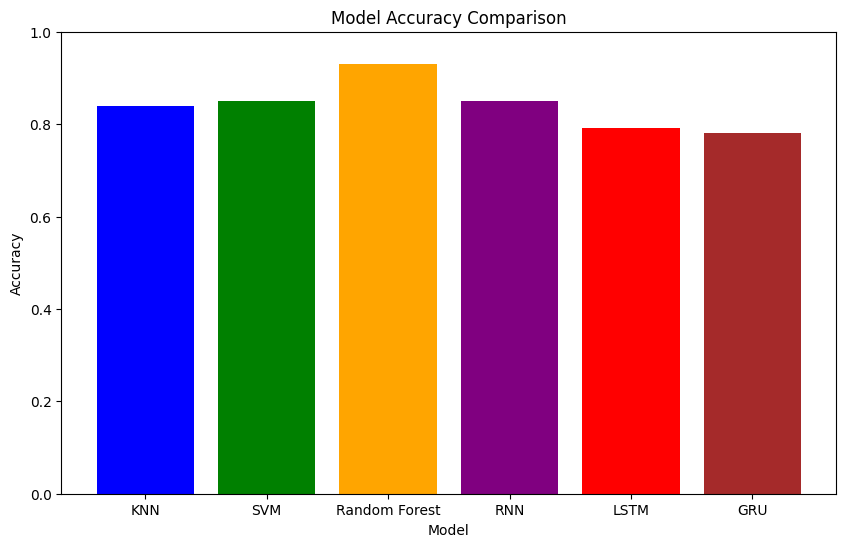

In [ ]:
model_names = ['KNN', 'SVM', 'Random Forest', 'RNN', 'LSTM', 'GRU']
accuracies = [knn_accuracy, svm_accuracy, rf_accuracy, rnn_accuracy, lstm_accuracy, gru_accuracy]

# Plotting the accuracies
plt.figure(figsize=(10, 6))
plt.bar(model_names, accuracies, color=['blue', 'green', 'orange', 'purple', 'red', 'brown'])
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)  # Since accuracy is between 0 and 1
plt.show()

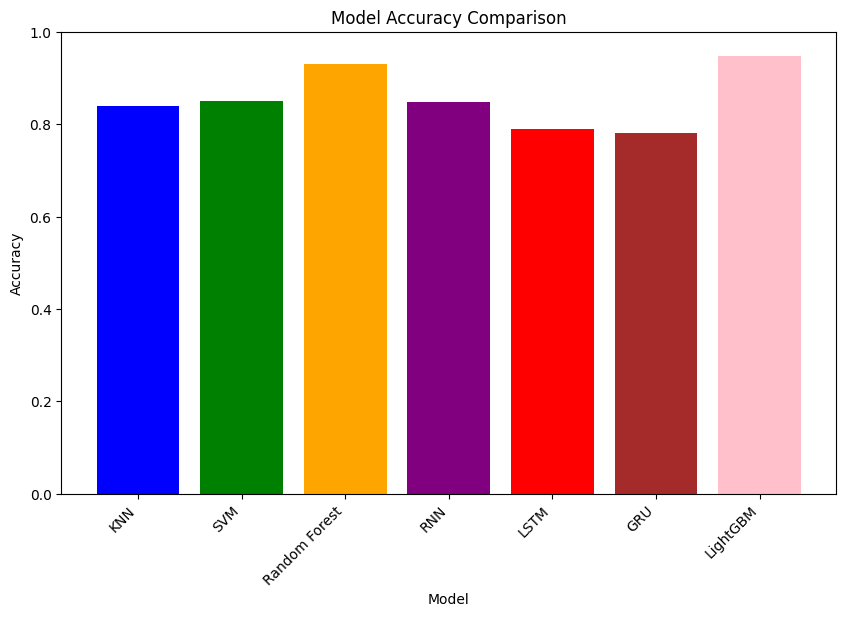

In [ ]:
import matplotlib.pyplot as plt

# Model names and their corresponding accuracies
model_names = ['KNN', 'SVM', 'Random Forest', 'RNN', 'LSTM', 'GRU', 'LightGBM']
accuracies = [knn_accuracy, svm_accuracy, rf_accuracy, rnn_accuracy, lstm_accuracy, gru_accuracy, 0.9475]  # Replace 0.9475 with the actual accuracy of LightGBM if needed

# Plotting the accuracies
plt.figure(figsize=(10, 6))
plt.bar(model_names, accuracies, color=['blue', 'green', 'orange', 'purple', 'red', 'brown', 'pink'])
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)  # Since accuracy is between 0 and 1
plt.xticks(rotation=45, ha='right')  # Rotate the x-axis labels for better readability
plt.show()


In [ ]:
import numpy as np

# Ensure X_train and X_test are numpy arrays (2D)
X_train = np.array(X_train)
X_test = np.array(X_test)


In [ ]:
# Fill missing values with the mean (if there are any)
X_train = np.nan_to_num(X_train, nan=np.nanmean(X_train, axis=0))
X_test = np.nan_to_num(X_test, nan=np.nanmean(X_test, axis=0))


In [ ]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)  # Flatten to (14280, 31)
X_test_flat = X_test.reshape(X_test.shape[0], -1)    # Similarly flatten test data


In [ ]:
import numpy as np
y_train_labels = np.argmax(y_train, axis=1)  # Convert one-hot to class labels
y_test_labels = np.argmax(y_test, axis=1)


In [ ]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import accuracy_score

# Flatten X_train and X_test
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Convert y_train and y_test to class labels
y_train_labels = np.argmax(y_train, axis=1)
y_test_labels = np.argmax(y_test, axis=1)

# Convert to DMatrix
dtrain = xgb.DMatrix(X_train_flat, label=y_train_labels)
dtest = xgb.DMatrix(X_test_flat, label=y_test_labels)

# Set parameters for multi-class classification
params = {
    'objective': 'multi:softmax',  # Use softmax for multi-class classification
    'num_class': 51,              # Number of classes
    'eval_metric': 'mlogloss',    # Log loss for multi-class
    'max_depth': 6,               # Maximum tree depth
    'learning_rate': 0.1          # Learning rate
}

# Train the XGBoost model
model_xgb = xgb.train(params, dtrain, num_boost_round=100)


# Train the XGBoost model
model_xgb = xgb.train(params, dtrain, num_boost_round=100)

# Predict on test data
y_pred_xgb = model_xgb.predict(dtest)

# Evaluate the model
accuracy_xgb = accuracy_score(y_test_labels, y_pred_xgb)
print(f"XGBoost Accuracy: {accuracy_xgb:.4f}")


KeyboardInterrupt: 

In [ ]:
!pip install --upgrade xgboost


In [ ]:
!pip install lightgbm


In [ ]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score

# Prepare LightGBM dataset
train_data = lgb.Dataset(X_train_flat, label=y_train_labels)
test_data = lgb.Dataset(X_test_flat, label=y_test_labels)

# Train LightGBM
params = {
    'objective': 'multiclass',
    'num_class': 51,
    'metric': 'multi_logloss',
    'max_depth': 8,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8
}
lgb_model = lgb.train(params, train_data, num_boost_round=200)

# Predict
y_pred = lgb_model.predict(X_test_flat)
y_pred_labels = np.argmax(y_pred, axis=1)

# Evaluate
accuracy = accuracy_score(y_test_labels, y_pred_labels)
print(f"LightGBM Accuracy: {accuracy:.4f}")


[LightGBM] [Warning] Provided parameters constrain tree depth (max_depth=8) without explicitly setting 'num_leaves'. This can lead to underfitting. To resolve this warning, pass 'num_leaves' (<=256) in params. Alternatively, pass (max_depth=-1) and just use 'num_leaves' to constrain model complexity.
[LightGBM] [Warning] Provided parameters constrain tree depth (max_depth=8) without explicitly setting 'num_leaves'. This can lead to underfitting. To resolve this warning, pass 'num_leaves' (<=256) in params. Alternatively, pass (max_depth=-1) and just use 'num_leaves' to constrain model complexity.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009687 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7905
[LightGBM] [Info] Number of data points in the train set: 14280, number of used features: 31
[LightGBM] [Info] Start training from score -3.917641
[LightGBM] [Info] Start training from score -3.886443

In [ ]:
from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMClassifier

# Define LightGBM classifier
lgb_clf = LGBMClassifier(objective='multiclass', num_class=51)

# Define hyperparameter grid
param_grid = {
    'max_depth': [6, 8, 10],
    'learning_rate': [0.05, 0.1, 0.2],
    'num_leaves': [31, 50],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 5, 10]
}

# Grid search with 3-fold cross-validation
grid_search = GridSearchCV(estimator=lgb_clf, param_grid=param_grid, cv=3, scoring='accuracy', verbose=1, n_jobs=-1)

# Fit the model
grid_search.fit(X_train_flat, y_train_labels)

# Get the best model and evaluate
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_flat)

# Evaluate accuracy
accuracy = accuracy_score(y_test_labels, y_pred)
print(f"Best LightGBM Accuracy after tuning: {accuracy:.4f}")


Fitting 3 folds for each of 324 candidates, totalling 972 fits


/usr/local/lib/python3.10/dist-packages/sklearn/utils/_tags.py:354: FutureWarning: The LGBMClassifier or classes from which it inherits use `_get_tags` and `_more_tags`. Please define the `__sklearn_tags__` method, or inherit from `sklearn.base.BaseEstimator` and/or other appropriate mixins such as `sklearn.base.TransformerMixin`, `sklearn.base.ClassifierMixin`, `sklearn.base.RegressorMixin`, and `sklearn.base.OutlierMixin`. From scikit-learn 1.7, not defining `__sklearn_tags__` will raise an error.
  warnings.warn(
